###<font color='red'>Made by Anton Rudchenko for ParKinSim (Parallel Kinematic Simulation) project.</font>

#<font color='orange'>This is an initial attempt of creation of linear regression model for solving inverse kinematic problem of Metrom (Pentapod) machine.

In [ ]:
#@title Imports

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score



pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

##Importing and preprocessing data collected from solving direct kinematics in simulation

In [ ]:
data = pd.read_csv('DKd.csv')

print(data)

         L1    L2    L3    L4    L5        X       Y        Z     RX     RY     RZ
0      14.0  16.0  15.0  15.0  15.0    6.225 -36.857  -29.095  0.255  0.039  0.045
1      13.0  16.0  15.0  15.0  15.0    6.911 -39.529  -26.396  0.274  0.043  0.048
2      12.0  16.0  15.0  15.0  15.0    7.764 -43.206  -23.034  0.301  0.047  0.052
3      11.0  16.0  15.0  15.0  15.0    8.963 -48.874  -18.280  0.342  0.054  0.058
4      11.0  15.0  15.0  15.0  15.0    7.614 -56.939  -13.149  0.400  0.042  0.046
...     ...   ...   ...   ...   ...      ...     ...      ...    ...    ...    ...
10187  87.0  64.0  19.0   8.0  89.0 -104.324  24.796 -110.492 -0.203 -0.400 -0.065
10188  87.0  64.0  19.0   7.0  89.0 -103.399  24.096 -111.093 -0.193 -0.390 -0.058
10189  87.0  64.0  19.0   6.0  89.0 -102.454  23.377 -111.680 -0.184 -0.381 -0.051
10190  87.0  64.0  19.0   5.0  89.0 -101.491  22.639 -112.253 -0.174 -0.372 -0.043
10191  87.0  64.0  19.0   4.0  89.0 -100.508  21.881 -112.813 -0.164 -0.363 -0.034

[10

There are some dublicate data entries from direct kinematics, it is a good practice to get rid of those.

In [ ]:
data = data.drop_duplicates()

print(data)

         L1    L2    L3    L4    L5        X       Y        Z     RX     RY     RZ
0      14.0  16.0  15.0  15.0  15.0    6.225 -36.857  -29.095  0.255  0.039  0.045
1      13.0  16.0  15.0  15.0  15.0    6.911 -39.529  -26.396  0.274  0.043  0.048
2      12.0  16.0  15.0  15.0  15.0    7.764 -43.206  -23.034  0.301  0.047  0.052
3      11.0  16.0  15.0  15.0  15.0    8.963 -48.874  -18.280  0.342  0.054  0.058
4      11.0  15.0  15.0  15.0  15.0    7.614 -56.939  -13.149  0.400  0.042  0.046
...     ...   ...   ...   ...   ...      ...     ...      ...    ...    ...    ...
10187  87.0  64.0  19.0   8.0  89.0 -104.324  24.796 -110.492 -0.203 -0.400 -0.065
10188  87.0  64.0  19.0   7.0  89.0 -103.399  24.096 -111.093 -0.193 -0.390 -0.058
10189  87.0  64.0  19.0   6.0  89.0 -102.454  23.377 -111.680 -0.184 -0.381 -0.051
10190  87.0  64.0  19.0   5.0  89.0 -101.491  22.639 -112.253 -0.174 -0.372 -0.043
10191  87.0  64.0  19.0   4.0  89.0 -100.508  21.881 -112.813 -0.164 -0.363 -0.034

[10

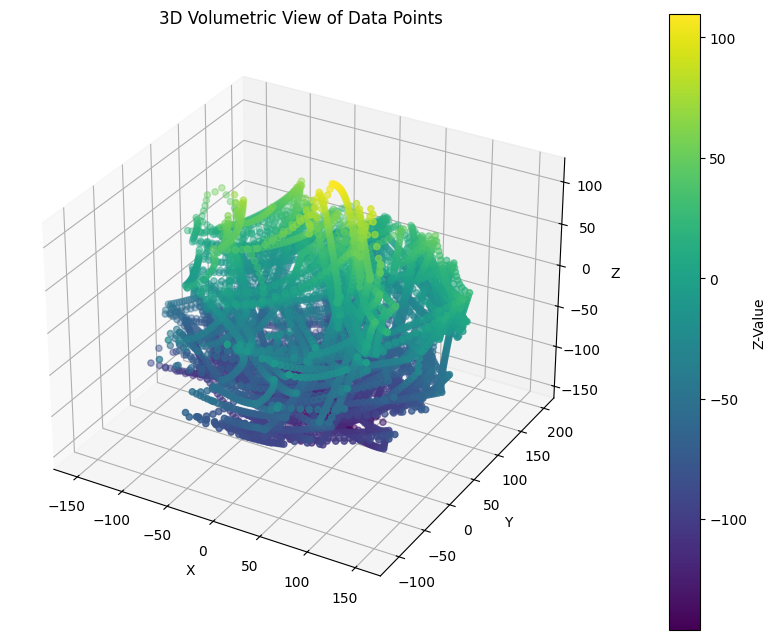

In [ ]:
#@title Plotting XYZ on volumetric plot
x = data['X']
y = data['Y']
z = data['Z']

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(x, y, z, c=z, cmap='viridis', marker='o')

ax.set_title('3D Volumetric View of Data Points')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

color_bar = fig.colorbar(scatter, ax=ax, pad=0.1)
color_bar.set_label('Z-Value')

plt.show()

<font color='red'>REMARK:</font> The dataset was collected again, after some changes were made to the mechanical design of the pentapod.

##Testing LR model

Performance Metrics:
Target X:
  Mean Squared Error: 110.9049
  R2 Score: 0.9756
Target Y:
  Mean Squared Error: 237.1461
  R2 Score: 0.9326
Target Z:
  Mean Squared Error: 185.5552
  R2 Score: 0.9225

Model Coefficients:
         L1        L2        L3        L4        L5
X -0.046482  1.331543  2.028468 -1.301911 -2.199146
Y -1.628010  1.050770  1.392492  0.944043  1.250134
Z -1.599719  0.605460  0.029356  0.578396  0.025540

Model Intercepts:
X     2.774710
Y   -50.556858
Z   -22.264776
dtype: float64


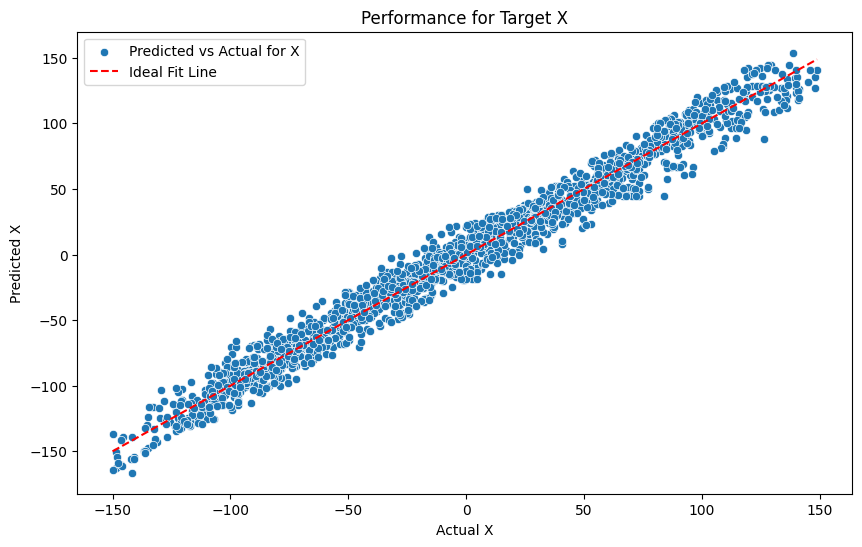

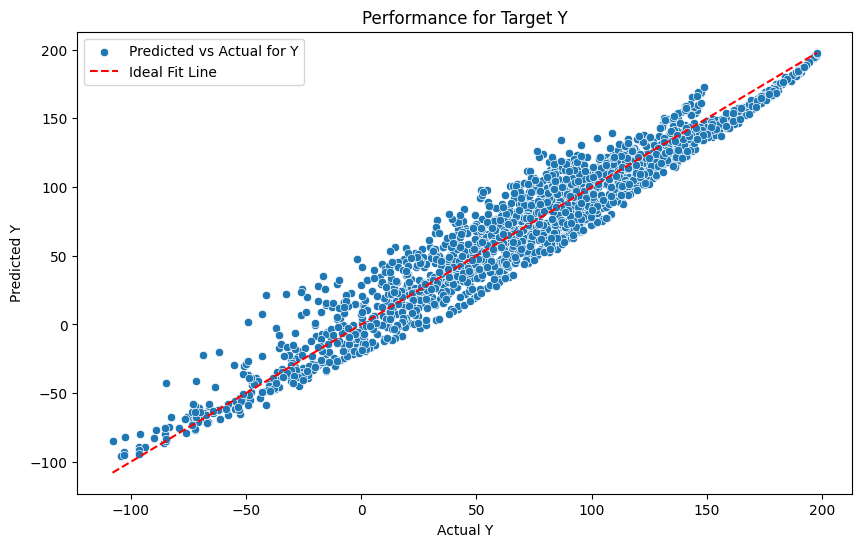

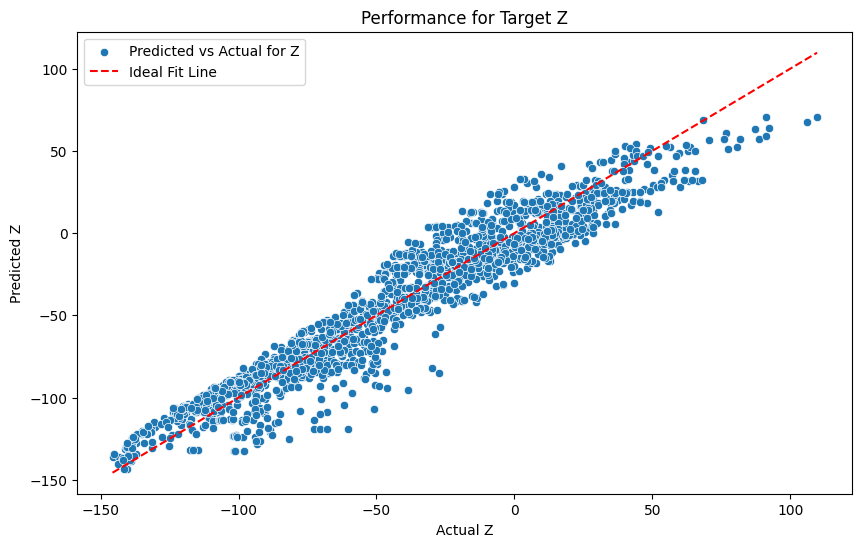

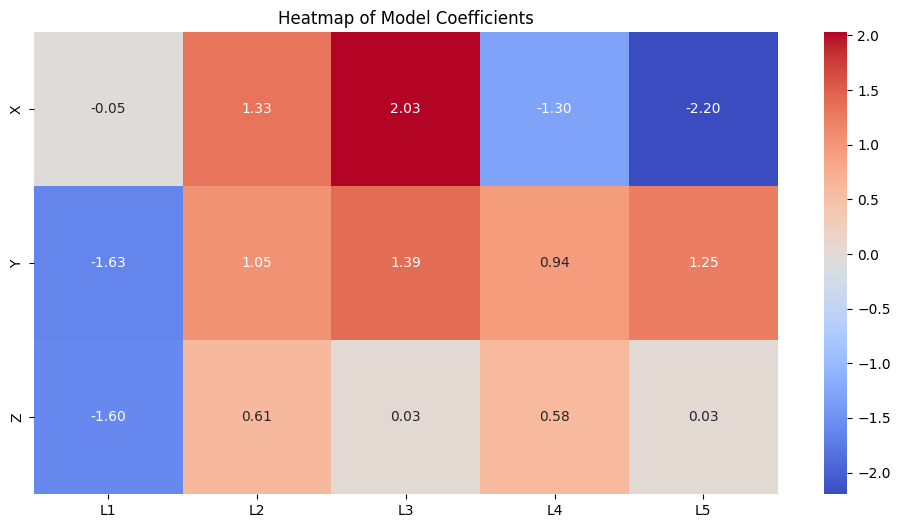

In [ ]:
features = data[['L1', 'L2', 'L3', 'L4', 'L5']]
labels = data[['X', 'Y', 'Z']]

# Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

# Linear Regression model definition and training
model = LinearRegression()
model.fit(X_train, y_train)

# Making predictions
y_pred = model.predict(X_test)

# Evaluating the model
mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

# Displaying metrics
print("Performance Metrics:")
for i, target in enumerate(['X', 'Y', 'Z']):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

# Accessing model coefficients and intercepts
coefficients = pd.DataFrame(model.coef_, columns=features.columns, index=labels.columns)
intercepts = pd.Series(model.intercept_, index=labels.columns)

print("\nModel Coefficients:")
print(coefficients)
print("\nModel Intercepts:")
print(intercepts)

# Visualizing performance
for i, target in enumerate(['X', 'Y', 'Z']):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

# Visualizing coefficients
plt.figure(figsize=(12, 6))
sns.heatmap(coefficients, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Model Coefficients")
plt.show()
